In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
from tensorflow.keras.models import load_model

resnet_model = load_model(
    "/content/drive/MyDrive/ResNet_Safe_Run/resnet_epoch_15.h5",
    compile=False   # IMPORTANT
)


In [ ]:
from tensorflow.keras.optimizers import Adam

resnet_model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model recompiled successfully")


Model recompiled successfully


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

BASE_DIR = "/content/drive/MyDrive/Final_Dataset"

train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    f"{BASE_DIR}/train",
    target_size=(224, 224),
    batch_size=32,
    class_mode="binary",
    subset="training",
    seed=42
)

val_gen = train_datagen.flow_from_directory(
    f"{BASE_DIR}/train",
    target_size=(224, 224),
    batch_size=32,
    class_mode="binary",
    subset="validation",
    seed=42
)


Found 10146 images belonging to 2 classes.
Found 2536 images belonging to 2 classes.


In [ ]:
import os
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, CSVLogger

SAVE_DIR = "/content/drive/MyDrive/ResNet_Safe_Run"

checkpoint_best = ModelCheckpoint(
    filepath=os.path.join(SAVE_DIR, "resnet_best.h5"),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

checkpoint_all = ModelCheckpoint(
    filepath=os.path.join(SAVE_DIR, "resnet_epoch_{epoch:02d}.h5"),
    save_freq="epoch",
    verbose=0
)

csv_logger = CSVLogger(
    os.path.join(SAVE_DIR, "training_log.csv"),
    append=True   # VERY IMPORTANT
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

callbacks = [checkpoint_best, checkpoint_all, csv_logger, early_stop]


In [ ]:
history = resnet_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=30,
    initial_epoch=15,
    callbacks=callbacks
)


Epoch 16/30
318/318 ━━━━━━━━━━━━━━━━━━━━ 0s 12s/step - accuracy: 0.7209 - loss: 0.5493 
Epoch 16: val_loss improved from inf to 0.51707, saving model to /content/drive/MyDrive/ResNet_Safe_Run/resnet_best.h5


318/318 ━━━━━━━━━━━━━━━━━━━━ 4884s 15s/step - accuracy: 0.7210 - loss: 0.5493 - val_accuracy: 0.7871 - val_loss: 0.5171
Epoch 17/30
318/318 ━━━━━━━━━━━━━━━━━━━━ 0s 270ms/step - accuracy: 0.7309 - loss: 0.5445
Epoch 17: val_loss improved from 0.51707 to 0.51664, saving model to /content/drive/MyDrive/ResNet_Safe_Run/resnet_best.h5


318/318 ━━━━━━━━━━━━━━━━━━━━ 115s 360ms/step - accuracy: 0.7309 - loss: 0.5445 - val_accuracy: 0.7721 - val_loss: 0.5166
Epoch 18/30
318/318 ━━━━━━━━━━━━━━━━━━━━ 0s 271ms/step - accuracy: 0.7331 - loss: 0.5375
Epoch 18: val_loss improved from 0.51664 to 0.49975, saving model to /content/drive/MyDrive/ResNet_Safe_Run/resnet_best.h5


318/318 ━━━━━━━━━━━━━━━━━━━━ 115s 362ms/step - accuracy: 0.7331 - loss: 0.5375 - val_accuracy: 0.7969 - val_loss: 0.4998
Epoch 19/30
220/318 ━━━━━━━━━━━━━━━━━━━━ 27s 279ms/step - accuracy: 0.7403 - loss: 0.5299

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
from tensorflow.keras.models import load_model

resnet_model = load_model(
    "/content/drive/MyDrive/ResNet_Safe_Run/resnet_epoch_18.h5",
    compile=False
)

print("Loaded model from epoch 18")


Loaded model from epoch 18


In [ ]:
from tensorflow.keras.optimizers import Adam

resnet_model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model recompiled")


Model recompiled


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

BASE_DIR = "/content/drive/MyDrive/Final_Dataset"

train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_gen = train_datagen.flow_from_directory(
    f"{BASE_DIR}/train",
    target_size=(224, 224),
    batch_size=32,
    class_mode="binary",
    subset="training",
    seed=42
)

val_gen = train_datagen.flow_from_directory(
    f"{BASE_DIR}/train",
    target_size=(224, 224),
    batch_size=32,
    class_mode="binary",
    subset="validation",
    seed=42
)


Found 10146 images belonging to 2 classes.
Found 2536 images belonging to 2 classes.


In [ ]:
import os
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, CSVLogger

SAVE_DIR = "/content/drive/MyDrive/ResNet_Safe_Run"

checkpoint_best = ModelCheckpoint(
    filepath=os.path.join(SAVE_DIR, "resnet_best.h5"),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

checkpoint_all = ModelCheckpoint(
    filepath=os.path.join(SAVE_DIR, "resnet_epoch_{epoch:02d}.h5"),
    save_freq="epoch"
)

csv_logger = CSVLogger(
    os.path.join(SAVE_DIR, "training_log.csv"),
    append=True
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

callbacks = [checkpoint_best, checkpoint_all, csv_logger, early_stop]


In [ ]:
history = resnet_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=30,
    initial_epoch=18,   # CONTINUE from epoch 18
    callbacks=callbacks
)


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 19/30
318/318 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.7429 - loss: 0.5280
Epoch 19: val_loss improved from inf to 0.50002, saving model to /content/drive/MyDrive/ResNet_Safe_Run/resnet_best.h5


318/318 ━━━━━━━━━━━━━━━━━━━━ 2328s 7s/step - accuracy: 0.7429 - loss: 0.5280 - val_accuracy: 0.7879 - val_loss: 0.5000
Epoch 20/30
318/318 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.7402 - loss: 0.5287
Epoch 20: val_loss did not improve from 0.50002


318/318 ━━━━━━━━━━━━━━━━━━━━ 1464s 5s/step - accuracy: 0.7402 - loss: 0.5287 - val_accuracy: 0.7721 - val_loss: 0.5123
Epoch 21/30
318/318 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.7365 - loss: 0.5337
Epoch 21: val_loss improved from 0.50002 to 0.49209, saving model to /content/drive/MyDrive/ResNet_Safe_Run/resnet_best.h5


318/318 ━━━━━━━━━━━━━━━━━━━━ 1470s 5s/step - accuracy: 0.7365 - loss: 0.5337 - val_accuracy: 0.7961 - val_loss: 0.4921
Epoch 22/30
318/318 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.7492 - loss: 0.5202
Epoch 22: val_loss did not improve from 0.49209


318/318 ━━━━━━━━━━━━━━━━━━━━ 1465s 5s/step - accuracy: 0.7491 - loss: 0.5202 - val_accuracy: 0.7772 - val_loss: 0.5017
Epoch 23/30
318/318 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.7454 - loss: 0.5116
Epoch 23: val_loss did not improve from 0.49209


318/318 ━━━━━━━━━━━━━━━━━━━━ 1555s 5s/step - accuracy: 0.7454 - loss: 0.5116 - val_accuracy: 0.7614 - val_loss: 0.5136
Epoch 24/30
318/318 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.7483 - loss: 0.5231
Epoch 24: val_loss did not improve from 0.49209


318/318 ━━━━━━━━━━━━━━━━━━━━ 1458s 5s/step - accuracy: 0.7483 - loss: 0.5231 - val_accuracy: 0.7796 - val_loss: 0.4949
Epoch 25/30
318/318 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.7371 - loss: 0.5206
Epoch 25: val_loss did not improve from 0.49209


318/318 ━━━━━━━━━━━━━━━━━━━━ 1478s 5s/step - accuracy: 0.7371 - loss: 0.5206 - val_accuracy: 0.7808 - val_loss: 0.4939


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


In [ ]:
MODEL_PATH = "/content/drive/MyDrive/ResNet_Safe_Run/resnet_best.h5"

resnet_model = load_model(MODEL_PATH)
print("Best ResNet model loaded")


Best ResNet model loaded


In [ ]:
TEST_DIR = "/content/drive/MyDrive/Final_Dataset/test"

test_datagen = ImageDataGenerator(rescale=1./255)

test_gen = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=(224, 224),
    batch_size=32,
    class_mode="binary",
    shuffle=False
)


Found 848 images belonging to 2 classes.


In [ ]:
test_gen.reset()

y_prob = resnet_model.predict(test_gen, verbose=1)
y_pred = (y_prob >= 0.5).astype(int).ravel()
y_true = test_gen.classes


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


27/27 ━━━━━━━━━━━━━━━━━━━━ 260s 9s/step


In [ ]:
acc  = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred)
rec  = recall_score(y_true, y_pred)
f1   = f1_score(y_true, y_pred)

print("ResNet50 (Best Model) Performance on Mendeley Test Set")
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=["Fresh", "Rotten"]))


ResNet50 (Best Model) Performance on Mendeley Test Set
Accuracy : 0.7665
Precision: 0.8128
Recall   : 0.7037
F1-score : 0.7543

Classification Report:
              precision    recall  f1-score   support

       Fresh       0.73      0.83      0.78       416
      Rotten       0.81      0.70      0.75       432

    accuracy                           0.77       848
   macro avg       0.77      0.77      0.77       848
weighted avg       0.77      0.77      0.77       848



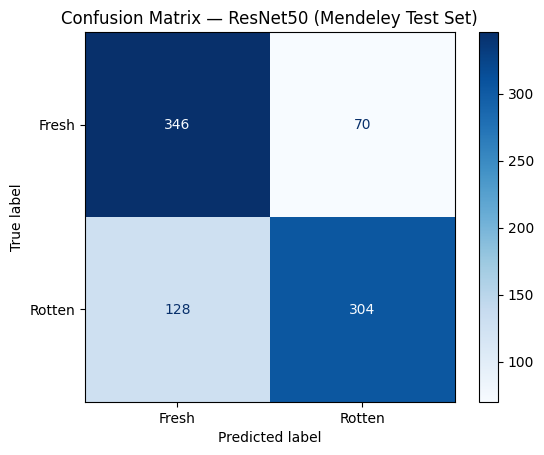

In [ ]:
cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fresh", "Rotten"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix — ResNet50 (Mendeley Test Set)")
plt.grid(False)
plt.show()


In [ ]:
log_path = "/content/drive/MyDrive/ResNet_Safe_Run/training_log.csv"
log_df = pd.read_csv(log_path)

log_df.head()


,epoch,accuracy,loss,val_accuracy,val_loss
0,0,0.529963,0.716936,0.723975,0.652204
1,1,0.576483,0.673219,0.738959,0.630879
2,2,0.616795,0.657514,0.776420,0.614202
3,3,0.624778,0.647745,0.766562,0.598173
4,4,0.659472,0.632191,0.765773,0.592186


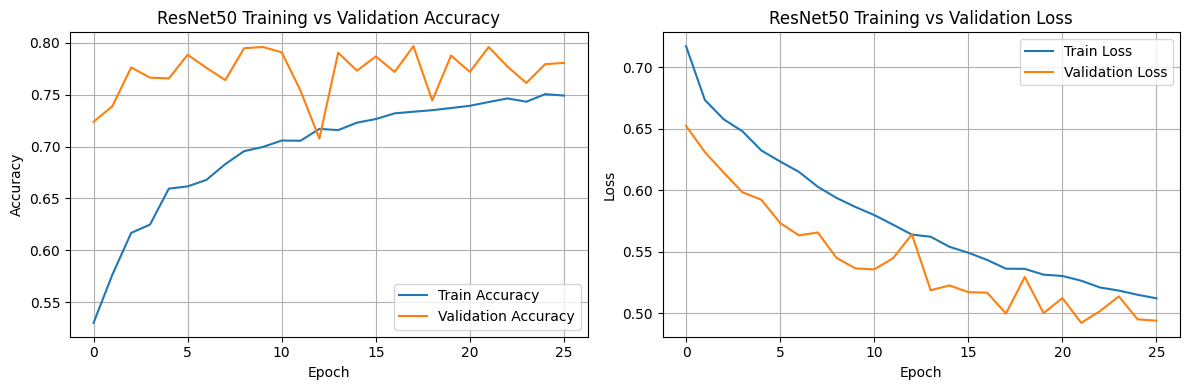

In [ ]:
plt.figure(figsize=(12,4))

# Accuracy
plt.subplot(1,2,1)
plt.plot(log_df["accuracy"], label="Train Accuracy")
plt.plot(log_df["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ResNet50 Training vs Validation Accuracy")
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1,2,2)
plt.plot(log_df["loss"], label="Train Loss")
plt.plot(log_df["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet50 Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


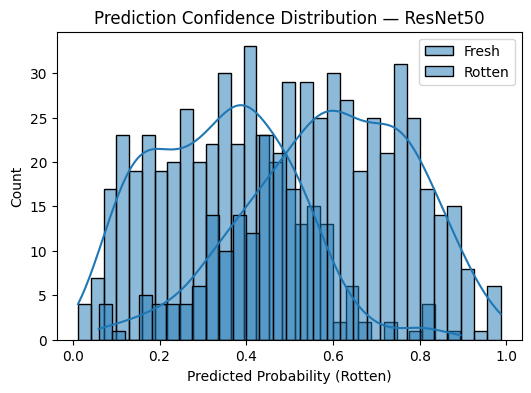

In [ ]:
plt.figure(figsize=(6,4))

sns.histplot(y_prob[y_true==0], bins=30, color="green", label="Fresh", kde=True)
sns.histplot(y_prob[y_true==1], bins=30, color="red", label="Rotten", kde=True)

plt.xlabel("Predicted Probability (Rotten)")
plt.ylabel("Count")
plt.title("Prediction Confidence Distribution — ResNet50")
plt.legend()
plt.show()


In [ ]:
resnet_model = load_model(
    "/content/drive/MyDrive/ResNet_Safe_Run/resnet_epoch_18.h5"
)


In [ ]:
test_gen.reset()

y_prob = resnet_model.predict(test_gen, verbose=1)
y_pred = (y_prob >= 0.5).astype(int).ravel()
y_true = test_gen.classes


27/27 ━━━━━━━━━━━━━━━━━━━━ 115s 4s/step


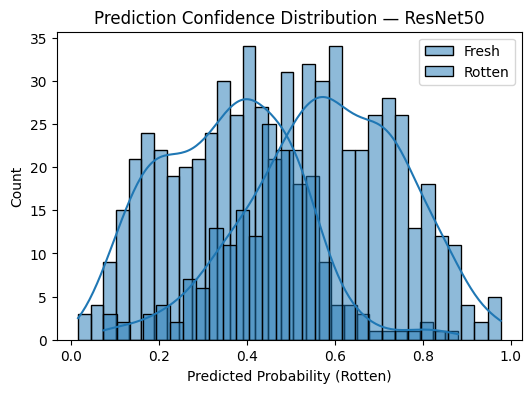

In [ ]:
plt.figure(figsize=(6,4))

sns.histplot(y_prob[y_true==0], bins=30, color="green", label="Fresh", kde=True)
sns.histplot(y_prob[y_true==1], bins=30, color="red", label="Rotten", kde=True)

plt.xlabel("Predicted Probability (Rotten)")
plt.ylabel("Count")
plt.title("Prediction Confidence Distribution — ResNet50")
plt.legend()
plt.show()
